# Online Retail – Phân tích dữ liệu (Phase 1–3)

**Đặt vấn đề:** lịch sử mua hàng **trước 01/06/2011** có dự đoán được chi tiêu trong **01/06–31/08/2011** của những khách đã xuất hiện trong lịch sử không? Nếu dự đoán được, doanh nghiệp biết trước khách nào sẽ chi nhiều để ưu tiên chăm sóc.

Notebook này gồm Phase 1–3: hiểu dữ liệu, tiền xử lý, tạo bảng khách hàng và phân tích thăm dò (EDA) trên tập train. Kết quả được lưu cạnh file dữ liệu để notebook predict (Phase 4–7) dùng tiếp.

Notebook chạy được theo hai cách đặt file: cấu trúc repo (notebook trong `analysis/`, dữ liệu trong `../dataset/`) hoặc đặt notebook chung một thư mục với file Excel, như khi nộp từng file.

## Thiết lập

In [1]:
import hashlib
import json
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import sklearn
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler

sns.set_theme(style='whitegrid', font='DejaVu Sans', font_scale=1.05)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
pd.set_option('display.max_columns', 60)
pd.set_option('display.float_format', '{:,.4f}'.format)

In [2]:
# Tìm dữ liệu ở thư mục hiện tại (nộp từng file) hoặc ../dataset (cấu trúc repo);
# tiền tố nhóm (NhomXX) lấy theo tên file nên đổi tên nhóm không phải sửa code
SEARCH_DIRS = [Path('.'), Path('../dataset')]
DATA_FILES = sorted(p for d in SEARCH_DIRS for p in d.glob('Nhom*_Online_Retail.xlsx'))
if len(DATA_FILES) != 1:
    raise FileNotFoundError(f'Cần đúng một file Nhom*_Online_Retail.xlsx trong {[str(d) for d in SEARCH_DIRS]}, '
                            f'tìm thấy {len(DATA_FILES)}.')
DATA_PATH = DATA_FILES[0]
DATA_DIR = DATA_PATH.parent
GROUP_PREFIX = DATA_PATH.stem.removesuffix('_Online_Retail')
MODEL_DATA_PATH = DATA_DIR / f'{GROUP_PREFIX}_Du_lieu_mo_hinh.csv'
OUT_DIR = DATA_DIR / f'{GROUP_PREFIX}_Ket_qua'   # kết quả luôn nằm cạnh file dữ liệu
FIG_DIR = OUT_DIR / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

EXPECTED_COLUMNS = ['InvoiceNo', 'StockCode', 'Description', 'Quantity',
                    'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']
EXPECTED_SHAPE = (541909, 8)
EXPECTED_SHA256 = '43465a06f2ccf7c8b5bd2892bc7defb52f97487934fe93b16ae4c3936424676d'
ITEM_CODE_PATTERN = r'\d{5}[A-Z]*'   # mã hàng hóa: 5 chữ số, có thể kèm hậu tố chữ cái

HISTORY_START = pd.Timestamp('2010-12-01')
CUTOFF = pd.Timestamp('2011-06-01')       # X tính trước mốc này
LABEL_END = pd.Timestamp('2011-09-01')    # y tính từ CUTOFF đến trước mốc này
# Kỳ kế tiếp, chỉ dùng ở Phase 7 để kiểm tra mô hình trên một quý chưa từng thấy;
# lịch sử vẫn dài 6 tháng như kỳ chính để mỗi biến giữ cùng ý nghĩa
NEXT_HISTORY_START = pd.Timestamp('2011-03-01')
NEXT_CUTOFF = pd.Timestamp('2011-09-01')
NEXT_LABEL_END = pd.Timestamp('2011-12-01')
RECENCY_BINS = [0, 30, 90, np.inf]
RECENCY_LABELS = ['≤30 ngày', '31–90 ngày', '>90 ngày']

TARGET = 'FutureSpend'
FEATURES = ['Monetary', 'Frequency', 'Recency', 'Tenure', 'Products', 'IsUK']
NUMERIC_FEATURES = [c for c in FEATURES if c != 'IsUK']   # IsUK là biến phân loại đã mã hóa 0/1
CATEGORICAL_FEATURES = ['IsUK']
RANDOM_STATE = 42
TEST_SIZE = 0.30
ALPHA = 0.05            # mức ý nghĩa cho p-value
MIN_ABS_CORR = 0.3      # biến số được chọn khi |r| nằm ngoài khoảng -0,3 đến 0,3

MAIN_COLOR = '#146482'
ACCENT_COLOR = '#b45538'
LIGHT_COLOR = '#b6d5df'

In [3]:
def pct(x, d=2):
    return f'{x * 100:.{d}f}%'

def save_fig(fig, name):
    """Lưu hình vào thư mục figures để báo cáo và slide dùng lại."""
    fig.tight_layout()
    fig.savefig(FIG_DIR / f'{name}.png', dpi=160, bbox_inches='tight')
    plt.show()

VERSIONS = {'python': platform.python_version(), 'numpy': np.__version__,
            'pandas': pd.__version__, 'scipy': scipy.__version__,
            'scikit-learn': sklearn.__version__, 'seaborn': sns.__version__}
print('Phiên bản thư viện:', VERSIONS)

Phiên bản thư viện: {'python': '3.12.3', 'numpy': '2.3.5', 'pandas': '2.2.3', 'scipy': '1.17.0', 'scikit-learn': '1.8.0', 'seaborn': '0.13.2'}


# Phase 1. Thu thập và hiểu dữ liệu
## Step 1. Nạp dữ liệu

Dữ liệu Online Retail do UCI cung cấp (Chen, 2015; DOI 10.24432/C5BW33; giấy phép CC BY 4.0), không tự thu thập. Một dòng là **một dòng hàng trong hóa đơn**, không phải một hóa đơn hay một khách hàng.

Mã SHA256 là "dấu vân tay" của file: trùng với mã ghi trong README nghĩa là file đang dùng đúng là bản gốc, chưa bị sửa.

In [4]:
df_raw = pd.read_excel(DATA_PATH, engine='openpyxl')
assert df_raw.columns.tolist() == EXPECTED_COLUMNS
assert df_raw.shape == EXPECTED_SHAPE, 'Kiểm tra lại phiên bản dataset.'
raw_sha256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
print(f'Số dòng: {df_raw.shape[0]:,} | Số cột: {df_raw.shape[1]}')
print('SHA256 khớp bản gốc:', raw_sha256 == EXPECTED_SHA256)
# Excel lưu CustomerID dạng số thực (17850.0); đổi kiểu chỉ khi hiển thị, df_raw giữ nguyên
df_raw.head().astype({'CustomerID': 'Int64'})

Số dòng: 541,909 | Số cột: 8
SHA256 khớp bản gốc: True


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.5500,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.3900,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.7500,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.3900,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.3900,17850,United Kingdom


In [5]:
df_raw.tail().astype({'CustomerID': 'Int64'})

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.8500,12680,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.1000,12680,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.1500,12680,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.1500,12680,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.9500,12680,France


In [6]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


## Step 2. Khám phá cấu trúc dữ liệu

`InvoiceNo`, `StockCode` và `CustomerID` là **mã định danh** dù Excel lưu một phần dưới dạng số; không tính toán số học trên các cột này.

In [7]:
# (nhóm, ý nghĩa, loại biến)
VAR_INFO = {
    'InvoiceNo':   ('Hóa đơn', 'Mã hóa đơn; bắt đầu bằng C là hóa đơn hủy', 'Định danh'),
    'StockCode':   ('Sản phẩm', 'Mã hàng', 'Định danh'),
    'Description': ('Sản phẩm', 'Tên hàng', 'Văn bản'),
    'Quantity':    ('Dòng hàng', 'Số lượng trên dòng hàng', 'Số'),
    'InvoiceDate': ('Hóa đơn', 'Ngày giờ lập hóa đơn', 'Thời gian'),
    'UnitPrice':   ('Dòng hàng', 'Đơn giá (GBP)', 'Số'),
    'CustomerID':  ('Khách hàng', 'Mã khách hàng', 'Định danh'),
    'Country':     ('Khách hàng', 'Quốc gia của khách', 'Phân loại'),
}

def value_range(col):
    """Phạm vi giá trị: min–max cho biến số/thời gian, số giá trị khác nhau cho biến chữ."""
    s = df_raw[col].dropna()
    if VAR_INFO[col][2] in ('Số', 'Thời gian'):
        return f'{s.min()} – {s.max()}'
    return f'{s.nunique():,} giá trị khác nhau'

var_table = pd.DataFrame({
    'group': [VAR_INFO[c][0] for c in df_raw.columns],
    'meaning': [VAR_INFO[c][1] for c in df_raw.columns],
    'kind': [VAR_INFO[c][2] for c in df_raw.columns],
    'dtype': df_raw.dtypes.astype(str).values,
    'range': [value_range(c) for c in df_raw.columns],
    'examples': [', '.join(map(str, df_raw[c].dropna().unique()[:3])) for c in df_raw.columns],
}, index=df_raw.columns)
var_table

,group,meaning,kind,dtype,range,examples
InvoiceNo,Hóa đơn,Mã hóa đơn; bắt đầu bằng C là hóa đơn hủy,Định danh,object,"25,900 giá trị khác nhau","536365, 536366, 536367"
StockCode,Sản phẩm,Mã hàng,Định danh,object,"4,070 giá trị khác nhau","85123A, 71053, 84406B"
Description,Sản phẩm,Tên hàng,Văn bản,object,"4,223 giá trị khác nhau","WHITE HANGING HEART T-LIGHT HOLDER, WHITE META..."
Quantity,Dòng hàng,Số lượng trên dòng hàng,Số,int64,-80995 – 80995,"6, 8, 2"
InvoiceDate,Hóa đơn,Ngày giờ lập hóa đơn,Thời gian,datetime64[ns],2010-12-01 08:26:00 – 2011-12-09 12:50:00,"2010-12-01 08:26:00, 2010-12-01 08:28:00, 2010..."
UnitPrice,Dòng hàng,Đơn giá (GBP),Số,float64,-11062.06 – 38970.0,"2.55, 3.39, 2.75"
CustomerID,Khách hàng,Mã khách hàng,Định danh,float64,"4,372 giá trị khác nhau","17850.0, 13047.0, 12583.0"
Country,Khách hàng,Quốc gia của khách,Phân loại,object,38 giá trị khác nhau,"United Kingdom, France, Australia"


In [8]:
# Số biến theo loại
var_table['kind'].value_counts().to_frame('variables')

,variables
kind,
Định danh,3
Số,2
Văn bản,1
Thời gian,1
Phân loại,1


In [9]:
NUM_COLS = ['Quantity', 'UnitPrice']

num_desc = df_raw[NUM_COLS].describe().T
num_desc['skew'] = df_raw[NUM_COLS].skew()
num_desc['%zero'] = (df_raw[NUM_COLS] == 0).mean() * 100
num_desc['%negative'] = (df_raw[NUM_COLS] < 0).mean() * 100
num_desc

,count,mean,std,min,25%,50%,75%,max,skew,%zero,%negative
Quantity,"541,909.0000",9.5522,218.0812,"-80,995.0000",1.0000,3.0000,10.0000,"80,995.0000",-0.2641,0.0000,1.9605
UnitPrice,"541,909.0000",4.6111,96.7599,"-11,062.0600",1.2500,2.0800,4.1300,"38,970.0000",186.5070,0.4641,0.0004


In [10]:
TEXT_COLS = ['InvoiceNo', 'StockCode', 'Description', 'Country']
df_raw[TEXT_COLS].astype('string').describe().T

,count,unique,top,freq
InvoiceNo,541909,25900,573585,1114
StockCode,541909,4070,85123A,2313
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369
Country,541909,38,United Kingdom,495478


In [11]:
# Phân bố dòng hàng theo quốc gia (10 quốc gia nhiều dòng nhất)
country_dist = pd.DataFrame({'count': df_raw['Country'].value_counts(),
                             '%': df_raw['Country'].value_counts(normalize=True) * 100})
country_dist.head(10)

,count,%
Country,,
United Kingdom,495478,91.4320
Germany,9495,1.7521
France,8557,1.5790
EIRE,8196,1.5124
Spain,2533,0.4674
Netherlands,2371,0.4375
Belgium,2069,0.3818
Switzerland,2002,0.3694
Portugal,1519,0.2803


In [12]:
# Tổng quan bộ dữ liệu
raw_invoice = df_raw['InvoiceNo'].astype('string').str.strip().str.upper()
raw_code = df_raw['StockCode'].astype('string').str.strip().str.upper()
is_cancelled = raw_invoice.str.startswith('C', na=False)
is_item_code = raw_code.str.fullmatch(ITEM_CODE_PATTERN, na=False)

overview = pd.Series({
    'Số dòng': f'{len(df_raw):,}',
    'Số cột': df_raw.shape[1],
    'Từ ngày': df_raw['InvoiceDate'].min(),
    'Đến ngày': df_raw['InvoiceDate'].max(),
    'Số hóa đơn': f"{df_raw['InvoiceNo'].nunique():,}",
    'Số mã hàng': f"{df_raw['StockCode'].nunique():,}",
    'Số mã khách': f"{df_raw['CustomerID'].nunique():,}",
    'Số quốc gia': df_raw['Country'].nunique(),
    'Ô khuyết (NaN)': f'{int(df_raw.isna().sum().sum()):,}',
    'Dòng trùng toàn bộ': f'{int(df_raw.duplicated().sum()):,}',
    'Bộ nhớ (MB)': round(df_raw.memory_usage(deep=True).sum() / 1024**2, 2),
}, name='value').to_frame()
overview

,value
Số dòng,"541,909"
Số cột,8
Từ ngày,2010-12-01 08:26:00
Đến ngày,2011-12-09 12:50:00
Số hóa đơn,"25,900"
Số mã hàng,"4,070"
Số mã khách,"4,372"
Số quốc gia,38
Ô khuyết (NaN),"136,534"
Dòng trùng toàn bộ,"5,268"


In [13]:
# Các vấn đề cần xử lý (phát hiện tự động trên file thực tế)
issues = pd.DataFrame([
    ('Thiếu CustomerID', f"{pct(df_raw['CustomerID'].isna().mean(), 3)} số dòng"),
    ('Thiếu Description', f"{df_raw['Description'].isna().sum():,} dòng"),
    ('Dòng trùng toàn bộ', f'{df_raw.duplicated().sum():,} dòng'),
    ('Hóa đơn hủy (InvoiceNo bắt đầu bằng C)', f'{is_cancelled.sum():,} dòng'),
    ('Quantity ≤ 0', f"{(df_raw['Quantity'] <= 0).sum():,} dòng"),
    ('UnitPrice ≤ 0', f"{(df_raw['UnitPrice'] <= 0).sum():,} dòng"),
    ('Mã không phải hàng hóa (POST, M, DOT, ...)', f'{(~is_item_code).sum():,} dòng'),
    ('Phân phối lệch mạnh (|skew| > 2)', ', '.join(num_desc.index[num_desc['skew'].abs() > 2])),
], columns=['issue', 'detail'])
issues

,issue,detail
0,Thiếu CustomerID,24.927% số dòng
1,Thiếu Description,"1,454 dòng"
2,Dòng trùng toàn bộ,"5,268 dòng"
3,Hóa đơn hủy (InvoiceNo bắt đầu bằng C),"9,288 dòng"
4,Quantity ≤ 0,"10,624 dòng"
5,UnitPrice ≤ 0,"2,517 dòng"
6,"Mã không phải hàng hóa (POST, M, DOT, ...)","2,995 dòng"
7,Phân phối lệch mạnh (|skew| > 2),UnitPrice


Trang UCI ghi bộ dữ liệu không khuyết, nhưng kiểm kê file thực tế cho thấy có khuyết, trùng và giao dịch hủy. Bài làm lấy kết quả kiểm kê file làm căn cứ.

# Phase 2. Tiền xử lý dữ liệu
## Step 3. Giá trị khuyết

Giá trị khuyết không chỉ là ô trống (NaN) mà còn có thể là ký hiệu như `?`, `N/A`, chuỗi rỗng. Kiểm tra cả hai dạng trước khi quyết định loại (`dropna`) hay thay thế (`fillna`/`replace`).

In [14]:
missing = df_raw.isna().sum().to_frame('missing_rows')
missing['missing_pct'] = 100 * missing['missing_rows'] / len(df_raw)
missing.to_csv(OUT_DIR / 'raw_missing.csv', encoding='utf-8-sig')
missing

,missing_rows,missing_pct
InvoiceNo,0,0.0000
StockCode,0,0.0000
Description,1454,0.2683
Quantity,0,0.0000
InvoiceDate,0,0.0000
UnitPrice,0,0.0000
CustomerID,135080,24.9267
Country,0,0.0000


In [15]:
# Khuyết "ẩn": ký hiệu đặc biệt trong các cột chữ (bỏ khoảng trắng, không phân biệt hoa thường)
MISSING_MARKERS = ['', '.', 'N/A', 'NA', 'NAN', 'NULL', 'NONE']

def is_missing_marker(series):
    """True khi ô là ký hiệu khuyết: một trong MISSING_MARKERS hoặc chỉ gồm dấu ? (?, ??, ...)."""
    text = series.astype('string').str.strip().str.upper()
    return (text.isin(MISSING_MARKERS) | text.str.fullmatch(r'\?+')).fillna(False).astype(bool)

hidden_missing = pd.Series({c: int(is_missing_marker(df_raw[c]).sum()) for c in TEXT_COLS},
                           name='marker_rows').to_frame()
hidden_missing

,marker_rows
InvoiceNo,0
StockCode,0
Description,55
Country,0


In [16]:
# Description khuyết (NaN hoặc ký hiệu): kiểm tra các dòng này có CustomerID và giá hay không
description_missing = df_raw['Description'].isna() | is_missing_marker(df_raw['Description'])
print(f'Description khuyết (NaN hoặc ký hiệu): {int(description_missing.sum()):,} dòng')
df_raw.loc[description_missing, ['Quantity', 'UnitPrice', 'CustomerID']].describe()

Description khuyết (NaN hoặc ký hiệu): 1,509 dòng


,Quantity,UnitPrice,CustomerID
count,"1,509.0000","1,509.0000",0.0000
mean,-11.4195,0.0000,NaN
std,278.1760,0.0000,NaN
min,"-3,667.0000",0.0000,NaN
25%,-29.0000,0.0000,NaN
50%,-3.0000,0.0000,NaN
75%,3.0000,0.0000,NaN
max,"5,568.0000",0.0000,NaN


- `CustomerID` khuyết **không thể thay thế** bằng trung bình hay mode (hoặc KNNImputer): đây là mã định danh, điền vào sẽ gán giao dịch của người lạ cho một khách có thật. Vì bài toán ở mức khách hàng, các dòng này bị loại (tương đương `dropna(subset=['CustomerID'])`).
- `Description` khuyết (NaN hoặc ký hiệu `?`) không tham gia mô hình nên không cần điền. Bảng trên cho thấy các dòng này đều không có `CustomerID` và có `UnitPrice` bằng 0 (dòng điều chỉnh kho), nên sẽ bị loại ở các bước lọc bên dưới.

## Step 4. Làm sạch và định dạng dữ liệu

In [17]:
# Mỗi quyết định gắn với một lý do nghiệp vụ
decisions = pd.DataFrame([
    ('Dòng trùng toàn bộ 8 cột', 'Loại',
     'Không có khóa dòng duy nhất nên đây là giả định làm sạch; kiểm tra độ nhạy bằng phương án giữ trùng'),
    ('Hóa đơn hủy (C...)', 'Loại', 'Phạm vi là chi tiêu mua hàng dương, không phải doanh thu thuần'),
    ('Quantity ≤ 0 hoặc UnitPrice ≤ 0', 'Loại', 'Hoàn trả, điều chỉnh hoặc hàng không tính tiền nằm ngoài phạm vi'),
    ('Thiếu CustomerID', 'Loại, không điền',
     'Là mã định danh; điền mean/mode sẽ gán giao dịch cho người khác'),
    ('Mã ngoài hàng hóa (POST, M, C2, ...)', 'Loại', 'Phí vận chuyển, dịch vụ hoặc điều chỉnh, không phải hàng hóa'),
    ('Thiếu Description', 'Giữ', 'Description không tham gia mô hình; không loại giao dịch hợp lệ vì thiếu mô tả'),
    ('Ngoại lệ lớn (khách mua sỉ)', 'Giữ', 'Có thể là giao dịch thật; giữ để đánh giá cả khách khó dự đoán'),
    ('Định dạng mã định danh', 'Chuyển sang chuỗi', 'Bỏ khoảng trắng, StockCode viết hoa; CustomerID bỏ phần .0'),
], columns=['issue', 'decision', 'reason'])
decisions

,issue,decision,reason
0,Dòng trùng toàn bộ 8 cột,Loại,Không có khóa dòng duy nhất nên đây là giả địn...
1,Hóa đơn hủy (C...),Loại,"Phạm vi là chi tiêu mua hàng dương, không phải..."
2,Quantity ≤ 0 hoặc UnitPrice ≤ 0,Loại,"Hoàn trả, điều chỉnh hoặc hàng không tính tiền..."
3,Thiếu CustomerID,"Loại, không điền",Là mã định danh; điền mean/mode sẽ gán giao dị...
4,"Mã ngoài hàng hóa (POST, M, C2, ...)",Loại,"Phí vận chuyển, dịch vụ hoặc điều chỉnh, không..."
5,Thiếu Description,Giữ,Description không tham gia mô hình; không loại...
6,Ngoại lệ lớn (khách mua sỉ),Giữ,Có thể là giao dịch thật; giữ để đánh giá cả k...
7,Định dạng mã định danh,Chuyển sang chuỗi,"Bỏ khoảng trắng, StockCode viết hoa; CustomerI..."


In [18]:
def keep_rows(frame, mask, step, audit_rows):
    """Giữ các dòng thỏa mask và ghi số dòng trước/sau; số dòng loại không đếm chồng."""
    kept = frame.loc[mask].copy()
    audit_rows.append({'step': step, 'before': len(frame),
                       'removed': len(frame) - len(kept), 'after': len(kept)})
    return kept

def clean_sales(data, drop_duplicates=True):
    """Lọc tuần tự theo bảng quyết định; trả về dữ liệu sạch, nhật ký lọc và các mã bị loại."""
    audit_rows = []
    sales = data.copy()
    if drop_duplicates:
        sales = keep_rows(sales, ~sales.duplicated(), '1 Loại dòng trùng toàn bộ', audit_rows)
    # Định dạng: mã định danh về chuỗi, bỏ khoảng trắng; ngày về kiểu datetime
    sales['InvoiceNo'] = sales['InvoiceNo'].astype('string').str.strip()
    sales['StockCode'] = sales['StockCode'].astype('string').str.strip().str.upper()
    sales['Country'] = sales['Country'].astype('string').str.strip()
    sales['InvoiceDate'] = pd.to_datetime(sales['InvoiceDate'], errors='coerce')

    is_cancelled = sales['InvoiceNo'].str.upper().str.startswith('C', na=False)
    sales = keep_rows(sales, ~is_cancelled, '2 Loại hóa đơn C', audit_rows)
    sales = keep_rows(sales, sales['Quantity'] > 0, '3 Giữ Quantity dương', audit_rows)
    sales = keep_rows(sales, sales['UnitPrice'] > 0, '4 Giữ UnitPrice dương', audit_rows)
    sales = keep_rows(sales, sales['CustomerID'].notna(), '5 Có CustomerID', audit_rows)
    is_item = sales['StockCode'].str.fullmatch(ITEM_CODE_PATTERN, na=False)
    excluded_codes = sales.loc[~is_item, 'StockCode'].value_counts()
    sales = keep_rows(sales, is_item, '6 Chỉ mã hàng hóa', audit_rows)
    has_date_country = sales['InvoiceDate'].notna() & sales['Country'].notna()
    sales = keep_rows(sales, has_date_country, '7 Có ngày và quốc gia', audit_rows)

    assert (sales['CustomerID'] % 1 == 0).all(), 'CustomerID phải là số nguyên trước khi đổi sang chuỗi'
    sales['CustomerID'] = sales['CustomerID'].astype('int64').astype('string')
    sales['LineSpend'] = sales['Quantity'] * sales['UnitPrice']
    return sales, pd.DataFrame(audit_rows), excluded_codes

In [19]:
df, audit, excluded_codes = clean_sales(df_raw)
assert (df['LineSpend'] > 0).all()
assert audit['removed'].sum() + len(df) == len(df_raw)
assert df.isna().sum()[['InvoiceNo', 'StockCode', 'InvoiceDate', 'CustomerID', 'Country']].sum() == 0
audit.to_csv(OUT_DIR / 'cleaning_audit.csv', index=False, encoding='utf-8-sig')
print(f"Sau làm sạch: {df.shape[0]:,} dòng | {df['CustomerID'].nunique():,} khách")
audit

Sau làm sạch: 391,150 dòng | 4,334 khách


,step,before,removed,after
0,1 Loại dòng trùng toàn bộ,541909,5268,536641
1,2 Loại hóa đơn C,536641,9251,527390
2,3 Giữ Quantity dương,527390,1336,526054
3,4 Giữ UnitPrice dương,526054,1176,524878
4,5 Có CustomerID,524878,132186,392692
5,6 Chỉ mã hàng hóa,392692,1542,391150
6,7 Có ngày và quốc gia,391150,0,391150


In [20]:
# Mã bị loại ở bước 6 (đếm trên phần dữ liệu còn lại sau bước 5)
excluded_codes.to_frame('rows')

,rows
StockCode,
POST,1099
M,279
C2,133
DOT,16
BANK CHARGES,12
PADS,3


In [21]:
# Kiểm tra kiểu dữ liệu sau định dạng
df.dtypes.to_frame('dtype').T

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,LineSpend
dtype,string[python],string[python],object,int64,datetime64[ns],float64,string[python],string[python],float64


In [22]:
# Kiểm tra tính nhất quán sau làm sạch: một hóa đơn phải thuộc đúng một khách
invoice_groups = df.groupby('InvoiceNo')
integrity = pd.Series({
    'Hóa đơn có > 1 khách': int((invoice_groups['CustomerID'].nunique() > 1).sum()),
    'Hóa đơn có > 1 quốc gia': int((invoice_groups['Country'].nunique() > 1).sum()),
    'Hóa đơn có > 1 mốc thời gian': int((invoice_groups['InvoiceDate'].nunique() > 1).sum()),
    'Khách có > 1 quốc gia': int((df.groupby('CustomerID')['Country'].nunique() > 1).sum()),
}, name='count').to_frame()
assert integrity.loc['Hóa đơn có > 1 khách', 'count'] == 0
integrity

,count
Hóa đơn có > 1 khách,0
Hóa đơn có > 1 quốc gia,0
Hóa đơn có > 1 mốc thời gian,30
Khách có > 1 quốc gia,8


## Step 5. Tạo bảng khách hàng dùng cho dự đoán

Dữ liệu gốc ở mức dòng hàng, còn câu hỏi ở mức khách hàng, nên phải gom nhóm (`groupby`) theo khách:

- Mỗi khách mua trước `CUTOFF` là một mẫu; X tính **hoàn toàn trước** `CUTOFF`.
- y = tổng `LineSpend` từ `CUTOFF` (bao gồm) đến `LABEL_END` (không bao gồm). Khách không mua trong cửa sổ y nhận **0** và vẫn được giữ.
- `Country` lấy mode trong lịch sử; nếu hòa, chọn theo thứ tự chữ cái. Khách xuất hiện lần đầu sau `CUTOFF` nằm ngoài phạm vi.
- Không đưa Quantity/UnitPrice của kỳ mục tiêu vào X, vì như vậy mô hình chỉ học lại công thức tính chi tiêu (rò rỉ mục tiêu).
- `RecencyGroup` chia `Recency` thành 3 bin bằng `pd.cut`. Mốc 30/90 ngày chọn theo nghiệp vụ (mua trong tháng, trong quý, lâu hơn) thay vì chia đều bằng `np.linspace`, vì Recency lệch phải nên chia đều sẽ dồn gần hết khách vào bin đầu.
- `IsUK` mã hóa one-hot bằng `get_dummies`.

In [23]:
def build_customers(sales, history_start=HISTORY_START, cutoff=CUTOFF, label_end=LABEL_END):
    """Gom lịch sử [history_start, cutoff) theo khách để tạo X; cộng chi tiêu trong [cutoff, label_end) để tạo y."""
    history = sales.loc[(sales['InvoiceDate'] >= history_start) & (sales['InvoiceDate'] < cutoff)].copy()
    future = sales.loc[(sales['InvoiceDate'] >= cutoff) & (sales['InvoiceDate'] < label_end)].copy()
    customers = history.groupby('CustomerID').agg(
        FirstPurchase=('InvoiceDate', 'min'), LastPurchase=('InvoiceDate', 'max'),
        Frequency=('InvoiceNo', 'nunique'), Monetary=('LineSpend', 'sum'),
        Products=('StockCode', 'nunique'))
    customers['Country'] = history.groupby('CustomerID')['Country'].agg(lambda s: sorted(s.mode())[0])
    customers['Recency'] = (cutoff - customers['LastPurchase']).dt.total_seconds() / 86400
    customers['Tenure'] = (cutoff - customers['FirstPurchase']).dt.total_seconds() / 86400
    future_spend = future.groupby('CustomerID')['LineSpend'].sum()
    customers[TARGET] = future_spend.reindex(customers.index, fill_value=0)
    customers['RecencyGroup'] = pd.cut(customers['Recency'], bins=RECENCY_BINS,
                                       labels=RECENCY_LABELS, include_lowest=True)
    # One-hot bằng get_dummies; chỉ giữ cột Country_UK vì hai cột dummy luôn cộng lại bằng 1
    country_group = customers['Country'].eq('United Kingdom').map({True: 'UK', False: 'Other'})
    country_dummies = pd.get_dummies(country_group, prefix='Country', dtype=int)
    customers['IsUK'] = country_dummies['Country_UK']
    return history, future, customers

In [24]:
history, future, customers = build_customers(df)
assert history['InvoiceDate'].max() < future['InvoiceDate'].min()
assert customers.index.is_unique and customers[TARGET].notna().all()
assert len(customers) == history['CustomerID'].nunique()
future_known = future.loc[future['CustomerID'].isin(customers.index)]
assert np.isclose(customers[TARGET].sum(), future_known['LineSpend'].sum())

new_future_customers = future.loc[~future['CustomerID'].isin(customers.index), 'CustomerID'].nunique()
print(f'Khách lịch sử: {len(customers):,} | dòng lịch sử: {len(history):,} | dòng cửa sổ y: {len(future):,}')
print(f'Khách mới trong cửa sổ y (ngoài phạm vi): {new_future_customers}')
customers.head()

Khách lịch sử: 2,716 | dòng lịch sử: 143,150 | dòng cửa sổ y: 79,977
Khách mới trong cửa sổ y (ngoài phạm vi): 598


,FirstPurchase,LastPurchase,Frequency,Monetary,Products,Country,Recency,Tenure,FutureSpend,RecencyGroup,IsUK
CustomerID,,,,,,,,,,,
12346,2011-01-18 10:01:00,2011-01-18 10:01:00,1,"77,183.6000",1,United Kingdom,133.5826,133.5826,0.0000,>90 ngày,1
12347,2010-12-07 14:57:00,2011-04-07 10:43:00,3,"1,823.4300",63,Iceland,54.5535,175.3771,967.4300,31–90 ngày,0
12348,2010-12-16 19:09:00,2011-04-05 10:47:00,3,"1,167.2400",21,Finland,56.5507,166.2021,0.0000,31–90 ngày,0
12350,2011-02-02 16:01:00,2011-02-02 16:01:00,1,294.4000,16,Norway,118.3326,118.3326,0.0000,>90 ngày,0
12352,2011-02-16 12:33:00,2011-03-22 16:08:00,4,641.5100,24,Norway,70.3278,104.4771,0.0000,31–90 ngày,0


In [25]:
# Định nghĩa đặc trưng; CustomerID chỉ là khóa, không phải biến đầu vào
FEATURE_INFO = {
    'Monetary':  ('Tổng chi tiêu lịch sử', 'GBP'),
    'Frequency': ('Số hóa đơn khác nhau', 'hóa đơn'),
    'Recency':   ('Số ngày từ lần mua cuối đến CUTOFF (có phần lẻ)', 'ngày'),
    'Tenure':    ('Số ngày từ lần mua đầu đến CUTOFF (có phần lẻ)', 'ngày'),
    'Products':  ('Số mã hàng khác nhau', 'mã hàng'),
    'IsUK':      ('Quốc gia phổ biến trong lịch sử là United Kingdom', '0/1'),
    TARGET:      ('Chi tiêu từ 01/06 đến trước 01/09/2011', 'GBP'),
}
assert TARGET not in FEATURES and 'CustomerID' not in FEATURES

feature_table = pd.DataFrame(FEATURE_INFO, index=['definition', 'unit']).T
feature_table['role'] = np.where(feature_table.index == TARGET, 'Mục tiêu (y)', 'Đầu vào (X)')
feature_table

,definition,unit,role
Monetary,Tổng chi tiêu lịch sử,GBP,Đầu vào (X)
Frequency,Số hóa đơn khác nhau,hóa đơn,Đầu vào (X)
Recency,Số ngày từ lần mua cuối đến CUTOFF (có phần lẻ),ngày,Đầu vào (X)
Tenure,Số ngày từ lần mua đầu đến CUTOFF (có phần lẻ),ngày,Đầu vào (X)
Products,Số mã hàng khác nhau,mã hàng,Đầu vào (X)
IsUK,Quốc gia phổ biến trong lịch sử là United Kingdom,0/1,Đầu vào (X)
FutureSpend,Chi tiêu từ 01/06 đến trước 01/09/2011,GBP,Mục tiêu (y)


In [26]:
customers['RecencyGroup'].value_counts().sort_index().to_frame('customers')

,customers
RecencyGroup,
≤30 ngày,1043
31–90 ngày,914
>90 ngày,759


## Step 6. Chia train/test

Chia 70/30 ngẫu nhiên theo mã khách. Từ đây, mọi phân tích liên quan đến y, chuẩn hóa và chọn mô hình **chỉ dùng tập train**; tập test chỉ mở ở Phase 6 để đo hiệu suất trên khách mô hình chưa thấy.

In [27]:
X = customers[FEATURES]
y = customers[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE)
assert set(X_train.index).isdisjoint(X_test.index)
customers['Split'] = np.where(customers.index.isin(X_train.index), 'train', 'test')

split_info = pd.DataFrame({
    'rows': [len(X_train), len(X_test)],
    'share': [len(X_train) / len(X), len(X_test) / len(X)],
    'y = 0 rate': [y_train.eq(0).mean(), y_test.eq(0).mean()],
}, index=['train', 'test'])
print(f'Không mua trong cửa sổ y: {int(y.eq(0).sum()):,} khách ({pct(y.eq(0).mean())})')
split_info

Không mua trong cửa sổ y: 1,370 khách (50.44%)


,rows,share,y = 0 rate
train,1901,0.6999,0.5097
test,815,0.3001,0.4920


## Step 7. Chuẩn hóa dữ liệu

Các đặc trưng có miền giá trị rất khác nhau (Monetary tới hàng chục nghìn GBP, IsUK chỉ 0/1). Bảng dưới so sánh hai cách chuẩn hóa min-max và z-score trên tập train. Min-max đưa về [0, 1] nhưng bị một khách cực lớn ép phần lớn khách về gần 0; z-score đưa về trung bình 0, độ lệch chuẩn 1.

Mô hình ở notebook predict dùng z-score (`StandardScaler`) đặt **trong Pipeline**, nên khi kiểm chứng chéo bộ chuẩn hóa chỉ học trung bình và độ lệch chuẩn từ phần train của từng fold. Bảng này chỉ để minh họa, không lưu lại.

In [28]:
# describe() tính std với mẫu số n - 1, còn StandardScaler chia cho n, nên std của z-score hiện 1,0003 thay vì đúng 1
scaling_demo = pd.DataFrame({
    'raw': X_train['Monetary'],
    'min_max': MinMaxScaler().fit_transform(X_train[['Monetary']]).ravel(),
    'z_score': StandardScaler().fit_transform(X_train[['Monetary']]).ravel(),
}).describe().T
scaling_demo[['mean', 'std', 'min', '50%', 'max']]

,mean,std,min,50%,max
raw,"1,203.3832","4,465.2752",2.9000,455.1800,"110,155.1200"
min_max,0.0109,0.0405,0.0000,0.0041,1.0000
z_score,-0.0000,1.0003,-0.2689,-0.1676,24.4062


## Step 8. Xuất dữ liệu

- Bảng khách hàng (kèm cột `Split`) là đầu vào của notebook predict.
- Hai bảng phụ dùng ở Phase 7, không được dùng ở EDA hay khi chọn mô hình:
  - Bảng khách khi **giữ** dòng trùng, để kiểm tra giả định làm sạch.
  - Bảng khách của **quý kế tiếp**: X từ lịch sử 01/03–31/08/2011, y = chi tiêu 01/09–30/11/2011. Mọi mốc dời thêm 3 tháng và lịch sử vẫn dài 6 tháng, nên `Monetary` hay `Frequency` có cùng ý nghĩa với kỳ chính. Bảng này dùng để kiểm tra mô hình trên một quý chưa từng thấy.

In [29]:
customers.reset_index().to_csv(MODEL_DATA_PATH, index=False, encoding='utf-8-sig')
print('Đã lưu dữ liệu mô hình:', MODEL_DATA_PATH)

Đã lưu dữ liệu mô hình: ../dataset/NhomXX_Du_lieu_mo_hinh.csv


In [30]:
# Phương án giữ dòng trùng (cùng mã khách và cùng phép chia)
df_keep_dup, _, _ = clean_sales(df_raw, drop_duplicates=False)
_, _, customers_keep_dup = build_customers(df_keep_dup)
assert set(customers_keep_dup.index) == set(customers.index)
customers_keep_dup.reset_index().to_csv(OUT_DIR / 'customers_keep_duplicates.csv',
                                        index=False, encoding='utf-8-sig')

# Quý kế tiếp: cùng hàm, dời cả ba mốc thêm 3 tháng; dữ liệu kết thúc 09/12/2011 nên y đủ trọn 3 tháng
assert df['InvoiceDate'].max() >= NEXT_LABEL_END
_, _, customers_next = build_customers(df, history_start=NEXT_HISTORY_START,
                                       cutoff=NEXT_CUTOFF, label_end=NEXT_LABEL_END)
customers_next.reset_index().to_csv(OUT_DIR / 'customers_next_quarter.csv', index=False, encoding='utf-8-sig')

extra_tables = pd.DataFrame({
    'customers': [len(customers), len(customers_keep_dup), len(customers_next)],
    'FutureSpend_total_GBP': [customers[TARGET].sum(), customers_keep_dup[TARGET].sum(),
                              customers_next[TARGET].sum()],
    'y = 0 rate': [customers[TARGET].eq(0).mean(), customers_keep_dup[TARGET].eq(0).mean(),
                   customers_next[TARGET].eq(0).mean()],
}, index=['chính (loại trùng, quý 6–8)', 'giữ dòng trùng (quý 6–8)', 'quý kế tiếp (quý 9–11)'])
extra_tables

,customers,FutureSpend_total_GBP,y = 0 rate
"chính (loại trùng, quý 6–8)",2716,"1,556,994.1200",0.5044
giữ dòng trùng (quý 6–8),2716,"1,559,833.5800",0.5044
quý kế tiếp (quý 9–11),2809,"2,436,419.3700",0.3955


# Phase 3. Phân tích thăm dò dữ liệu (EDA) – tập train
## Step 9. Thống kê mô tả

Phân tích liên quan đến y **chỉ dùng tập train**. Không dùng y_test để tìm biến hay chọn mô hình. Biểu đồ theo tháng và theo quốc gia mô tả dữ liệu lịch sử (phần X), không chứa y.

Bảng gồm ba nhóm đại lượng: hướng trung tâm (mean, median, mode), độ phân tán (range, quartile, IQR, variance, std, CV) và hình dáng (skewness, kurtosis).

In [31]:
train_df = customers.loc[X_train.index].copy()

In [32]:
descriptive = train_df[NUMERIC_FEATURES + [TARGET]].describe().T
descriptive['median'] = train_df[descriptive.index].median()
descriptive['mode'] = [train_df[c].mode().iloc[0] for c in descriptive.index]
descriptive['range'] = descriptive['max'] - descriptive['min']
descriptive['IQR'] = descriptive['75%'] - descriptive['25%']
descriptive['variance'] = train_df[descriptive.index].var()    # phương sai mẫu, chia n - 1
descriptive['CV_pct'] = descriptive['std'] / descriptive['mean'] * 100
descriptive['skew'] = train_df[descriptive.index].skew()
descriptive['kurtosis'] = train_df[descriptive.index].kurt()   # pandas trả về kurtosis dư (phân phối chuẩn = 0)
descriptive.to_csv(OUT_DIR / 'descriptive_train.csv', encoding='utf-8-sig')
descriptive

,count,mean,std,min,25%,50%,75%,max,median,mode,range,IQR,variance,CV_pct,skew,kurtosis
Monetary,"1,901.0000","1,203.3832","4,465.2752",2.9000,236.0200,455.1800,"1,028.5600","110,155.1200",455.1800,45.0000,"110,152.2200",792.5400,"19,938,682.7705",371.0601,14.9135,280.1395
Frequency,"1,901.0000",2.6528,3.6766,1.0000,1.0000,2.0000,3.0000,59.0000,2.0000,1.0000,58.0000,2.0000,13.5173,138.5920,6.9483,73.8798
Recency,"1,901.0000",63.8265,52.9231,0.3465,19.4965,49.4514,97.5944,181.5882,49.4514,8.4778,181.2417,78.0979,"2,800.8540",82.9171,0.8004,-0.4853
Tenure,"1,901.0000",111.8435,54.8337,0.3528,67.6368,118.3889,168.5514,181.6431,118.3889,20.3910,181.2903,100.9146,"3,006.7361",49.0272,-0.3063,-1.1663
Products,"1,901.0000",40.2188,50.1879,1.0000,12.0000,25.0000,52.0000,879.0000,25.0000,1.0000,878.0000,40.0000,"2,518.8237",124.7870,5.4652,59.8753
FutureSpend,"1,901.0000",533.3173,"2,819.6560",0.0000,0.0000,0.0000,435.7800,"65,895.1200",0.0000,0.0000,"65,895.1200",435.7800,"7,950,459.7568",528.7014,17.6072,362.5787


- `Monetary`, `Frequency`, `Products` và `FutureSpend` có mean lớn hơn median nhiều lần và skew dương lớn: phân phối **lệch phải mạnh** (Mode < Median < Mean). CV trên 100% cho thấy độ phân tán rất lớn so với trung bình.
- Kurtosis rất lớn ở `Monetary` và `FutureSpend` cho thấy ngoại lệ nghiêm trọng (vài khách mua sỉ).
- `Recency` lệch phải nhẹ; `Tenure` hơi lệch trái (skew âm, mean < median) vì nhiều khách đã mua từ những tháng đầu của lịch sử.
- Median và mode của `FutureSpend` đều bằng 0 vì hơn một nửa khách không mua trong cửa sổ y.
- Mode chỉ có ý nghĩa với biến rời rạc (`Frequency`, `Products`, `FutureSpend`). `Recency` và `Tenure` là số ngày có phần lẻ nên gần như mỗi khách một giá trị, mode của chúng không dùng để diễn giải.

In [33]:
# Ngoại lệ theo IQR (quy tắc box plot): ngoài [Q1 - 1.5·IQR, Q3 + 1.5·IQR]; chỉ đếm, không loại
iqr_rows = []
for c in NUMERIC_FEATURES + [TARGET]:
    q1, q3 = train_df[c].quantile([0.25, 0.75])
    low, high = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    n_out = int(((train_df[c] < low) | (train_df[c] > high)).sum())
    iqr_rows.append({'variable': c, 'lower_fence': low, 'upper_fence': high,
                     'outliers': n_out, 'outlier_pct': 100 * n_out / len(train_df)})
outliers = pd.DataFrame(iqr_rows).set_index('variable')
outlier_threshold = float(outliers.loc[TARGET, 'upper_fence'])
n_outliers = int(outliers.loc[TARGET, 'outliers'])
outliers

,lower_fence,upper_fence,outliers,outlier_pct
variable,,,,
Monetary,-952.7900,"2,217.3700",177,9.3109
Frequency,-2.0000,6.0000,130,6.8385
Recency,-97.6503,214.7413,0,0.0000
Tenure,-83.7351,319.9233,0,0.0000
Products,-48.0000,112.0000,124,6.5229
FutureSpend,-653.6700,"1,089.4500",173,9.1005


Ngoại lệ được **giữ lại**: đây là khách mua sỉ thật, không phải lỗi nhập liệu, và chính là nhóm doanh nghiệp quan tâm nhất. Hệ quả cần nhớ khi đánh giá mô hình: MSE/RMSE bình phương sai số nên sẽ bị vài khách này chi phối; vì vậy báo cáo thêm MAE.

In [34]:
# Mức tập trung chi tiêu: nhóm khách chi nhiều nhất chiếm bao nhiêu phần tổng chi tiêu
def top_share(values, top_pct):
    ranked = values.sort_values(ascending=False)
    n_top = max(1, int(round(len(ranked) * top_pct)))
    return ranked.head(n_top).sum() / ranked.sum()

TOP_PCTS = [0.01, 0.05, 0.10, 0.20]
concentration = pd.DataFrame(
    {c: [top_share(train_df[c], p) for p in TOP_PCTS] for c in ['Monetary', TARGET]},
    index=[f'top {p:.0%} khách' for p in TOP_PCTS])
concentration.map(pct)

,Monetary,FutureSpend
top 1% khách,29.89%,38.04%
top 5% khách,46.97%,57.74%
top 10% khách,57.84%,69.85%
top 20% khách,70.99%,84.55%


Chi tiêu tập trung mạnh: khoảng 10% khách chi nhiều nhất chiếm gần 60% `Monetary` và khoảng 70% `FutureSpend` trên train.

## Step 10. Trực quan phân phối

Mỗi biểu đồ trả lời một câu hỏi: line plot cho diễn biến theo thời gian, bar chart để so sánh quốc gia, histogram và box plot cho phân phối và ngoại lệ.

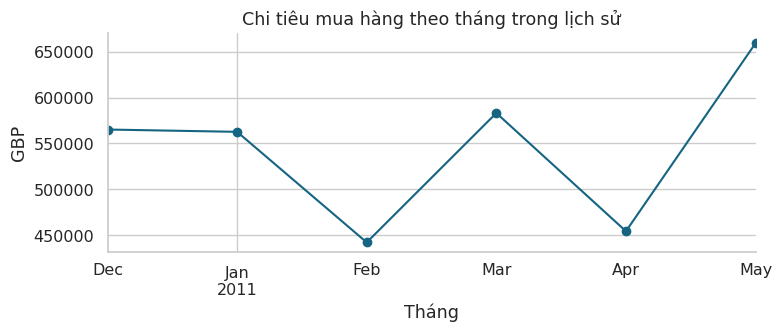

In [35]:
monthly = history.set_index('InvoiceDate')['LineSpend'].resample('MS').sum()
fig, ax = plt.subplots(figsize=(8, 3.5))
monthly.plot(ax=ax, marker='o', color=MAIN_COLOR)
ax.set(title='Chi tiêu mua hàng theo tháng trong lịch sử', xlabel='Tháng', ylabel='GBP')
save_fig(fig, '01_monthly')

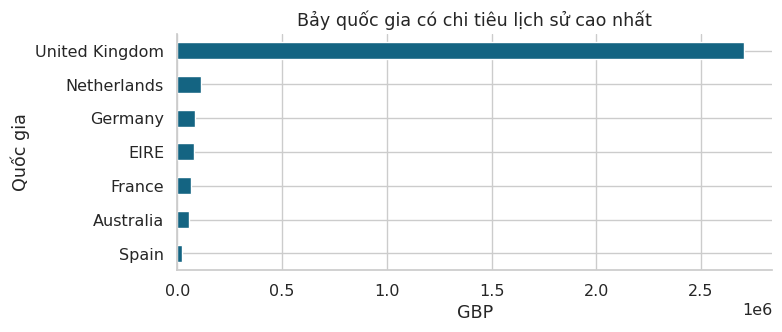

Tổng chi tiêu lịch sử: 3,267,003.28 GBP | United Kingdom: 82.78%


In [36]:
country_totals = history.groupby('Country')['LineSpend'].sum().sort_values(ascending=False)
uk_share = country_totals.loc['United Kingdom'] / country_totals.sum()
fig, ax = plt.subplots(figsize=(8, 3.5))
country_totals.head(7).sort_values().plot.barh(ax=ax, color=MAIN_COLOR)
ax.set(title='Bảy quốc gia có chi tiêu lịch sử cao nhất', xlabel='GBP', ylabel='Quốc gia')
save_fig(fig, '02_country')
print(f"Tổng chi tiêu lịch sử: {history['LineSpend'].sum():,.2f} GBP | United Kingdom: {pct(uk_share)}")

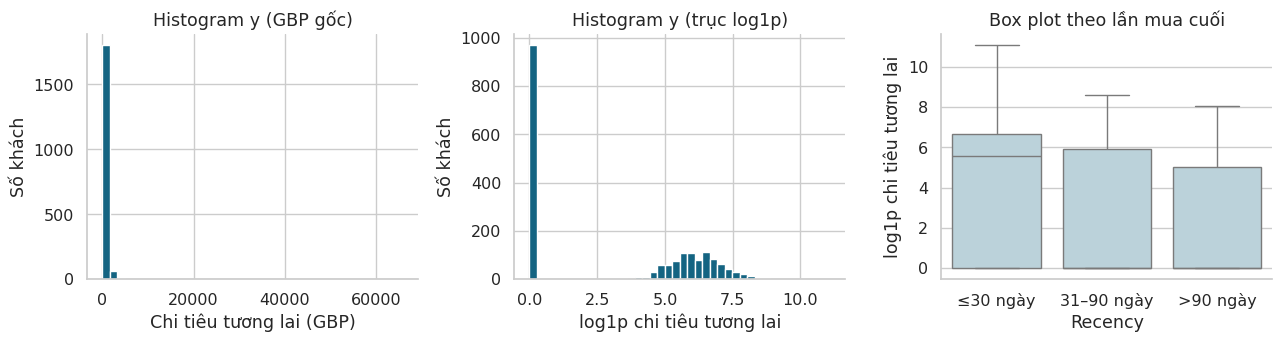

In [37]:
# Trục GBP gốc gần như không đọc được vì lệch phải; log1p(y) = log(1 + y) chỉ đổi trục nhìn, giữ được y = 0
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
axes[0].hist(y_train, bins=40, color=MAIN_COLOR)
axes[0].set(xlabel='Chi tiêu tương lai (GBP)', ylabel='Số khách', title='Histogram y (GBP gốc)')
axes[1].hist(np.log1p(y_train), bins=40, color=MAIN_COLOR)
axes[1].set(xlabel='log1p chi tiêu tương lai', ylabel='Số khách', title='Histogram y (trục log1p)')
sns.boxplot(x=train_df['RecencyGroup'], y=np.log1p(y_train), ax=axes[2], color=LIGHT_COLOR)
axes[2].set(xlabel='Recency', ylabel='log1p chi tiêu tương lai', title='Box plot theo lần mua cuối')
save_fig(fig, '03_distribution')

## Step 11. Tương quan với mục tiêu

Pearson đo liên hệ **tuyến tính**, không phải quan hệ nhân quả. Quy tắc chọn biến (áp dụng trên tập train):

- Biến số: giữ khi |r| ≥ 0,3 (ngoài khoảng −0,3 đến 0,3) **và** p-value < 0,05.
- Biến phân loại (`IsUK`): dùng ANOVA ở Step 12, giữ khi p-value < 0,05.

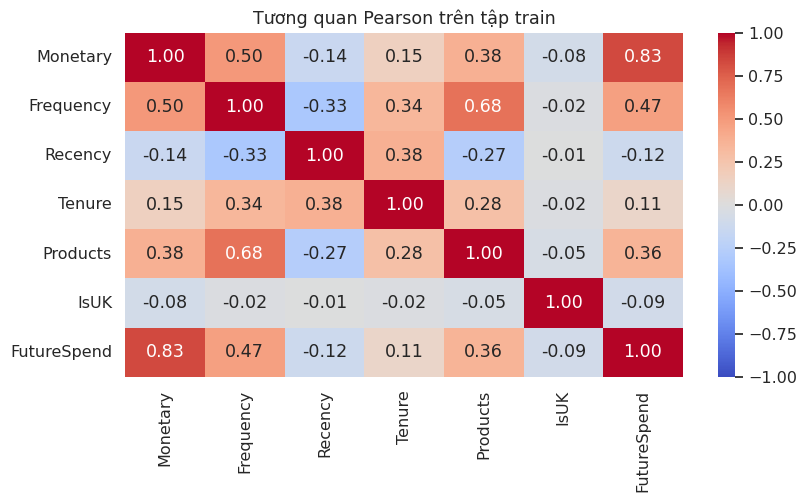

In [38]:
corr = train_df[FEATURES + [TARGET]].corr()
fig, ax = plt.subplots(figsize=(8.5, 5.2))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, center=0, ax=ax)
ax.set_title('Tương quan Pearson trên tập train')
save_fig(fig, '04_correlation')

In [39]:
def corr_strength(r):
    """Mức tương quan theo độ lớn |r|."""
    r = abs(r)
    return 'Mạnh' if r >= 0.8 else 'Vừa' if r >= 0.5 else 'Yếu' if r >= 0.3 else 'Không'

def p_strength(p):
    """Mức bằng chứng của p-value."""
    return 'Strong' if p < 0.001 else 'Moderate' if p < 0.05 else 'Weak' if p < 0.1 else 'No'

pearson_rows = []
for c in NUMERIC_FEATURES:
    r, p = stats.pearsonr(train_df[c], train_df[TARGET])
    pearson_rows.append({'feature': c, 'r': r, 'p_value': p, 'strength': corr_strength(r),
                         'p_evidence': p_strength(p), 'selected': abs(r) >= MIN_ABS_CORR and p < ALPHA})
pearson = pd.DataFrame(pearson_rows).sort_values('r', key=np.abs, ascending=False).reset_index(drop=True)
pearson.to_csv(OUT_DIR / 'pearson_train.csv', index=False)
# p-value hiển thị dạng khoa học vì rất nhỏ; 0.00e+00 nghĩa là nhỏ hơn mức máy tính biểu diễn được
pearson.assign(p_value=pearson['p_value'].map('{:.2e}'.format))

,feature,r,p_value,strength,p_evidence,selected
0,Monetary,0.8306,0.00e+00,Mạnh,Strong,True
1,Frequency,0.4660,4.25e-103,Yếu,Strong,True
2,Products,0.3582,1.24e-58,Yếu,Strong,True
3,Recency,-0.1240,5.88e-08,Không,Strong,False
4,Tenure,0.1090,1.91e-06,Không,Strong,False


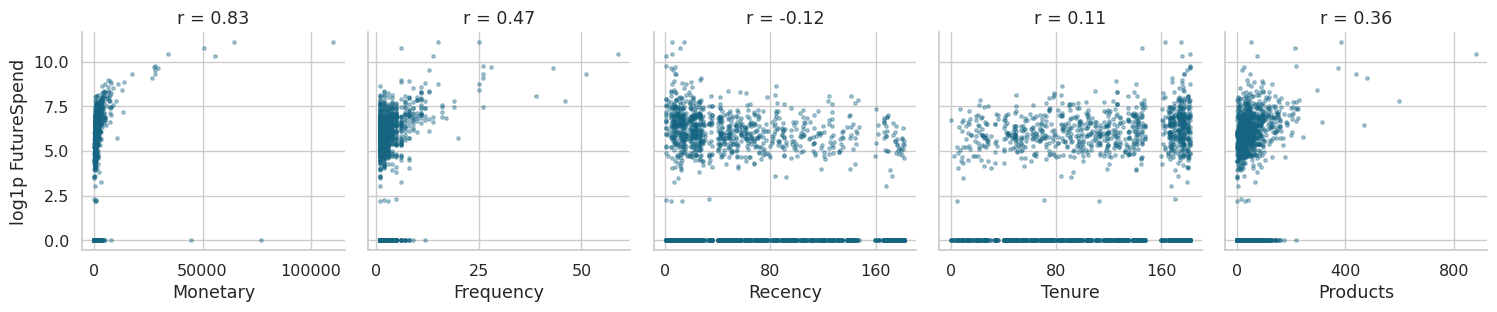

In [40]:
# Scatter plot của từng biến số với y (trục log1p để thấy rõ phần đông khách)
fig, axes = plt.subplots(1, len(NUMERIC_FEATURES), figsize=(15, 3.3), sharey=True)
for ax, c in zip(axes, NUMERIC_FEATURES):
    ax.scatter(train_df[c], np.log1p(train_df[TARGET]), s=6, alpha=0.35, color=MAIN_COLOR)
    ax.set(xlabel=c, title=f"r = {corr.loc[c, TARGET]:.2f}")
    ax.xaxis.set_major_locator(plt.MaxNLocator(3))
axes[0].set_ylabel('log1p FutureSpend')
save_fig(fig, '05_scatter_features')

`Monetary` tương quan mạnh nhất với y, tiếp theo là `Frequency` và `Products` ở mức yếu–vừa. `Recency` và `Tenure` có |r| < 0,3 nên không đạt ngưỡng tuyến tính, dù p-value rất nhỏ: với hơn 1.800 khách, một tương quan nhỏ cũng "có ý nghĩa thống kê", nên phải xem cả độ lớn của r chứ không chỉ p-value.

## Step 12. Gom nhóm và ANOVA

Gom nhóm để xem y khác nhau thế nào giữa các nhóm khách; ANOVA kiểm tra sự khác biệt về **trung bình** y giữa các nhóm có ý nghĩa thống kê hay không (H0: trung bình các nhóm bằng nhau).

In [41]:
# buy_rate = tỷ lệ khách có mua trong cửa sổ y
group_table = train_df.groupby('RecencyGroup', observed=True)[TARGET].agg(
    ['count', 'mean', 'median', ('buy_rate', lambda s: s.gt(0).mean())])
group_table

,count,mean,median,buy_rate
RecencyGroup,,,,
≤30 ngày,731,"1,031.2346",266.1000,0.6457
31–90 ngày,631,283.8345,0.0000,0.4707
>90 ngày,539,150.1004,0.0000,0.3024


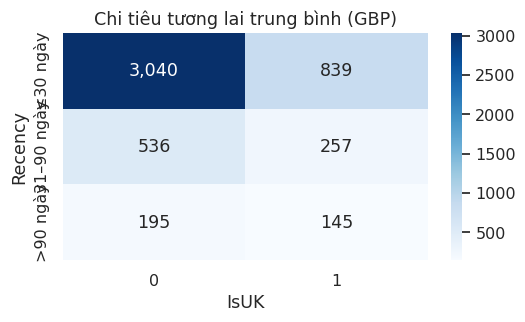

IsUK,0,1
RecencyGroup,,
≤30 ngày,"3,039.5141",838.5361
31–90 ngày,536.2005,256.8269
>90 ngày,194.9830,145.2058


In [42]:
recency_uk_pivot = train_df.pivot_table(index='RecencyGroup', columns='IsUK', values=TARGET,
                                        aggfunc='mean', observed=True)
fig, ax = plt.subplots(figsize=(5.5, 3.4))
sns.heatmap(recency_uk_pivot, annot=True, fmt=',.0f', cmap='Blues', ax=ax)
ax.set(title='Chi tiêu tương lai trung bình (GBP)', xlabel='IsUK', ylabel='Recency')
save_fig(fig, '06_pivot_heatmap')
recency_uk_pivot

In [43]:
def anova_by(column):
    """ANOVA một nhân tố: y theo các nhóm của một biến phân loại (scipy.stats.f_oneway)."""
    groups = [part[TARGET] for _, part in train_df.groupby(column, observed=True)]
    f_value, p_value = stats.f_oneway(*groups)
    return {'variable': column, 'groups': len(groups), 'F': f_value, 'p_value': p_value,
            'conclusion': 'Có khác biệt' if p_value < ALPHA else 'Không khác biệt'}

anova = pd.DataFrame([anova_by('IsUK'), anova_by('RecencyGroup')]).set_index('variable')
anova.assign(p_value=anova['p_value'].map('{:.2e}'.format))

,groups,F,p_value,conclusion
variable,,,,
IsUK,2,15.9876,6.62e-05,Có khác biệt
RecencyGroup,3,19.2066,5.52e-09,Có khác biệt


In [44]:
# So từng cặp nhóm Recency để biết khác biệt nằm ở đâu
pair_rows = []
for i, a in enumerate(RECENCY_LABELS):
    for b in RECENCY_LABELS[i + 1:]:
        f_value, p_value = stats.f_oneway(train_df.loc[train_df['RecencyGroup'] == a, TARGET],
                                          train_df.loc[train_df['RecencyGroup'] == b, TARGET])
        pair_rows.append({'pair': f'{a} vs {b}', 'F': f_value, 'p_value': p_value,
                          'conclusion': 'Có khác biệt' if p_value < ALPHA else 'Không khác biệt'})
anova_pairs = pd.DataFrame(pair_rows).set_index('pair')
anova_pairs.assign(p_value=anova_pairs['p_value'].map('{:.2e}'.format))

,F,p_value,conclusion
pair,,,
≤30 ngày vs 31–90 ngày,17.4674,3.11e-05,Có khác biệt
≤30 ngày vs >90 ngày,20.9029,5.30e-06,Có khác biệt
31–90 ngày vs >90 ngày,22.3804,2.51e-06,Có khác biệt


- Tỷ lệ khách có mua giảm dần theo Recency (khoảng 65% → 47% → 30%), và ANOVA xác nhận trung bình y khác nhau giữa các nhóm Recency. Trong khi đó Pearson của `Recency` chỉ khoảng −0,12: quan hệ giữa Recency và y **không tuyến tính** (giảm mạnh ở 30 ngày đầu rồi chững lại). Đây là lý do thử thêm hồi quy đa thức ở notebook predict.
- `IsUK` có p < 0,05 nên được giữ theo quy tắc. Bảng pivot cho thấy khách ngoài UK chi trung bình cao hơn (nhiều khách sỉ nước ngoài), nhưng tương quan với y chỉ khoảng −0,09, tức `IsUK` một mình giải thích rất ít biến thiên của y.
- ANOVA giả định phân phối trong nhóm gần chuẩn và phương sai các nhóm gần bằng nhau; y lệch phải mạnh nên p-value chỉ dùng để tham khảo, kết luận chính dựa thêm vào box plot và bảng gom nhóm.

## Step 13. Kết luận EDA: biến quan trọng

In [45]:
selected_numeric = pearson.loc[pearson['selected'], 'feature'].tolist()
selected_categorical = [c for c in CATEGORICAL_FEATURES if anova.loc[c, 'p_value'] < ALPHA]
SELECTED_FEATURES = [c for c in FEATURES if c in selected_numeric + selected_categorical]
SLR_FEATURE = pearson.loc[0, 'feature']   # biến có |r| lớn nhất dùng cho hồi quy đơn biến
print('Biến số được chọn:', selected_numeric)
print('Biến phân loại được chọn:', selected_categorical)
print('Biến dùng cho MLR:', SELECTED_FEATURES, '| Biến cho SLR:', SLR_FEATURE)

Biến số được chọn: ['Monetary', 'Frequency', 'Products']
Biến phân loại được chọn: ['IsUK']
Biến dùng cho MLR: ['Monetary', 'Frequency', 'Products', 'IsUK'] | Biến cho SLR: Monetary


In [46]:
analysis_summary = {
    'source_url': 'https://archive.ics.uci.edu/dataset/352/online+retail',
    'doi': '10.24432/C5BW33', 'license': 'CC BY 4.0', 'sha256': raw_sha256,
    'versions': VERSIONS, 'random_state': RANDOM_STATE, 'raw_shape': list(df_raw.shape),
    'missing': df_raw.isna().sum().to_dict(), 'duplicates': int(df_raw.duplicated().sum()),
    'clean_rows': len(df), 'clean_customers': int(df['CustomerID'].nunique()),
    'history_rows': len(history), 'future_rows': len(future),
    'customer_samples': len(customers), 'train_samples': len(X_train), 'test_samples': len(X_test),
    'zero_target_samples': int(y.eq(0).sum()), 'zero_target_pct': float(y.eq(0).mean() * 100),
    'history_spend_GBP': float(history['LineSpend'].sum()),
    'uk_history_share_pct': float(uk_share * 100),
    'new_future_customers': int(new_future_customers),
    'next_quarter_customers': len(customers_next),
    'next_quarter_window': [str(NEXT_HISTORY_START.date()), str(NEXT_CUTOFF.date()), str(NEXT_LABEL_END.date())],
    'outlier_threshold_train': outlier_threshold, 'train_outlier_count': n_outliers,
    'anova_train': {k: {'F': float(v['F']), 'p_value': float(v['p_value'])} for k, v in anova.iterrows()},
    'selected_features': SELECTED_FEATURES, 'slr_feature': SLR_FEATURE,
}
(OUT_DIR / 'analysis_summary.json').write_text(
    json.dumps(analysis_summary, ensure_ascii=False, indent=2), encoding='utf-8')
print('Đã lưu kết quả tại:', OUT_DIR)

Đã lưu kết quả tại: ../dataset/NhomXX_Ket_qua
